# SparkEV – Module 2: Predictive Charging Recommendation

```
SparkEV - Module 2: Predictive Charging Recommendation
======================================================
Three predictive models + a decision layer.

  Model A  Charging-level model   : how much energy will the user need before the
                                    next charge?  -> recommended target SoC
                                    (regression, quantile regression, 4-class level)
  Model B  Urgency model          : will this session be time-critical or flexible?
                                    (3-class)  -> fast vs. slow / queue-tolerant option
  Model C  Congestion model       : how busy will a charging site be next hour?
                                    (regression + 3-class wait-risk)

Decision layer (recommend_option) ranks candidate stations using A + B + C.
```

**Datasets** (semicolon-delimited, decimal comma): `Dataset1_charging_reports`, `Dataset2_user_predictions`, `Dataset3_session_predictions`. Dataset 4 (hourly breakdown) is not needed – it is a re-expression of Dataset 1 sessions.

**Evaluation protocol:** chronological 70/15/15 split (train/validation/test), hyper-parameters tuned on validation, final models refit on train+validation, all reported metrics on the untouched test split. All features are knowable at plug-in time (user history uses `shift(1)`), because Datasets 3/4 columns such as `charging_time`, `idle_time` and `SoC_diff` are deterministic functions of Dataset 1.

⏱ Full run takes roughly 10–15 minutes on a single CPU (mostly hyper-parameter search).

## 0. Setup

In [1]:
import json, os, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report, mean_pinball_loss)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RNG = 42
CHARGE_EFF = 0.88          # energy_session -> energy stored (derived from Dataset 3)
RESERVE_PCT = 15           # safety reserve used to define the "needed" charge level
SOC_MAX = 95               # dataset charges to 95 %

LEVEL_BINS = [-1, 50, 70, 85, 100]
LEVEL_NAMES = ["Top-up (<=50%)", "Moderate (50-70%)", "High (70-85%)", "Near-full (85-95%)"]
URG_BINS = [0, 1.5, 4, 1e12]
URG_NAMES = ["Time-critical", "Moderate", "Flexible"]
WAIT_NAMES = ["Low", "Medium", "High"]


In [2]:
DATA_DIR = os.path.join("..", "..", "data", "raw")   # folder containing the CSV files
OUT_DIR  = "./module2_outputs"
os.makedirs(OUT_DIR, exist_ok=True)


## 1. Load + Clean

Loads the semicolon/decimal-comma CSVs and joins sessions, user attributes and derived session columns.

In [3]:
def load(data_dir):
    rd = lambda f: pd.read_csv(os.path.join(data_dir, f), sep=";", decimal=",", na_values=["NA"])
    d1 = rd("Dataset1_charging_reports.csv")
    d2 = rd("Dataset2_user_predictions.csv")
    d3 = rd("Dataset3_session_predictions.csv")
    return d1, d2, d3


def build_sessions(d1, d2, d3):
    m = d1.merge(d3, on=["user_id", "session_id"], how="inner").merge(d2, on="user_id", how="left")
    m = m.dropna(subset=["plugout_time", "charging_time", "battery_capacity", "charging_power"]).copy()
    m["pt"] = pd.to_datetime(m["plugin_time"])
    m["po"] = pd.to_datetime(m["plugout_time"])
    m = m.sort_values(["user_id", "pt"]).reset_index(drop=True)
    m["slack"] = m["connection_time"] / m["charging_time"]          # dwell / needed charging time
    return m


## 2. Features  (Everything Is Known At Plug-In Time; History Uses Shift(1))

Feature engineering. Habit features describe what the user did after previous plug-ins on the same weekday/hour; none look at the current or future session.

In [4]:
def add_features(m):
    g = m.groupby("user_id", sort=False)
    m["hour"] = m.pt.dt.hour
    m["dow"] = m.pt.dt.dayofweek
    m["month"] = m.pt.dt.month
    m["weekend"] = (m.dow >= 5).astype(int)
    m["hour_sin"] = np.sin(2 * np.pi * m.hour / 24)
    m["hour_cos"] = np.cos(2 * np.pi * m.hour / 24)
    m["loc_code"] = m["location"].astype("category").cat.codes
    m["cur_soc_need"] = m["SoC_diff"]                 # % battery being charged now (from arrival SoC)
    m["cur_energy"] = m["energy_session"]
    m["cur_charge_time"] = m["charging_time"]

    # --- user history (strictly past sessions) ---
    for k in (1, 2, 3):
        m[f"soc_lag{k}"] = g["SoC_diff"].shift(k)
    m["soc_hist_mean"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().mean())
    m["soc_hist_std"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().std())
    m["soc_roll5"] = g["SoC_diff"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    m["soc_hist_dow_mean"] = m.groupby(["user_id", "dow"])["SoC_diff"].transform(
        lambda s: s.shift(1).expanding().mean())
    m["n_prev"] = g.cumcount()
    prev_po = g["po"].shift(1)
    m["hrs_since_prev_plugout"] = (m.pt - prev_po).dt.total_seconds() / 3600
    m["conn_lag1"] = g["connection_time"].shift(1)
    m["conn_hist_mean"] = g["connection_time"].transform(lambda s: s.shift(1).expanding().mean())
    m["conn_hist_med"] = g["connection_time"].transform(lambda s: s.shift(1).expanding().median())
    m["conn_hist_dow_mean"] = m.groupby(["user_id", "dow"])["connection_time"].transform(
        lambda s: s.shift(1).expanding().mean())
    m["conn_hist_hour_mean"] = m.groupby(["user_id", "hour"])["connection_time"].transform(
        lambda s: s.shift(1).expanding().mean())
    # habit features: what happened after this user's previous plug-ins on the same weekday / hour
    m["gap_prev_days"] = (m.pt - g["pt"].shift(1)).dt.total_seconds() / 86400
    m["_next_gap"] = (g["pt"].shift(-1) - m.pt).dt.total_seconds() / 86400
    m["_next_soc"] = g["SoC_diff"].shift(-1)
    m["gap_hist_mean"] = g["gap_prev_days"].transform(lambda s: s.expanding().mean())
    m["gap_hist_med"] = g["gap_prev_days"].transform(lambda s: s.expanding().median())
    m["after_dow_gap_mean"] = m.groupby(["user_id", "dow"])["_next_gap"].transform(lambda s: s.shift(1).expanding().mean())
    m["after_dow_soc_mean"] = m.groupby(["user_id", "dow"])["_next_soc"].transform(lambda s: s.shift(1).expanding().mean())
    m["after_dow_soc_med"] = m.groupby(["user_id", "dow"])["_next_soc"].transform(lambda s: s.shift(1).expanding().median())
    m["after_hour_soc_mean"] = m.groupby(["user_id", "hour"])["_next_soc"].transform(lambda s: s.shift(1).expanding().mean())
    m["after_soc_mean"] = g["_next_soc"].transform(lambda s: s.shift(1).expanding().mean())
    m["soc_hist_med"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().median())
    m["soc_hist_q75"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().quantile(0.75))
    m["soc_hist_q90"] = g["SoC_diff"].transform(lambda s: s.shift(1).expanding().quantile(0.90))
    m["soc_per_day_hist"] = m["soc_hist_mean"] / m["gap_hist_mean"].clip(lower=0.1)
    m["slack_lag1"] = g["slack"].shift(1)
    m["slack_hist_med"] = g["slack"].transform(lambda s: s.shift(1).expanding().median())
    m["hist_hour_mean"] = g["hour"].transform(lambda s: s.shift(1).expanding().mean())

    # --- targets ---
    m["next_soc_need"] = g["SoC_diff"].shift(-1)                       # demand until next charge
    m["next_gap_days"] = (g["pt"].shift(-1) - m.pt).dt.total_seconds() / 86400
    m["target_level_soc"] = np.clip(m.next_soc_need + RESERVE_PCT, 0, SOC_MAX)
    m["level_class"] = pd.cut(m.target_level_soc, LEVEL_BINS, labels=False)
    m["urg_class"] = pd.cut(m.slack, URG_BINS, labels=False, right=False)
    return m


FEATS_COMMON = ["hour", "dow", "month", "weekend", "hour_sin", "hour_cos", "loc_code",
                "battery_capacity", "charging_power", "cur_soc_need", "cur_energy",
                "cur_charge_time", "n_prev", "hrs_since_prev_plugout", "hist_hour_mean"]
FEATS_A = FEATS_COMMON + ["soc_lag1", "soc_lag2", "soc_lag3", "soc_hist_mean", "soc_hist_std",
                          "soc_roll5", "soc_hist_dow_mean", "conn_hist_mean", "gap_prev_days", "gap_hist_mean",
                          "gap_hist_med", "after_dow_gap_mean", "after_dow_soc_mean", "after_dow_soc_med",
                          "after_hour_soc_mean", "after_soc_mean", "soc_hist_med", "soc_hist_q75",
                          "soc_hist_q90", "soc_per_day_hist"]
FEATS_B = FEATS_COMMON + ["conn_lag1", "conn_hist_mean", "conn_hist_med", "conn_hist_dow_mean",
                          "conn_hist_hour_mean", "slack_lag1", "slack_hist_med", "soc_hist_mean"]


def chrono_split(df, col="pt", fr=(0.70, 0.15)):
    """Chronological split (no shuffling) -> honest estimate of future performance."""
    c1 = df[col].quantile(fr[0]); c2 = df[col].quantile(fr[0] + fr[1])
    return df[df[col] <= c1], df[(df[col] > c1) & (df[col] <= c2)], df[df[col] > c2]


## 3. Metric Helpers

Metric helpers and a small validation-set hyper-parameter search.

In [5]:
def reg_metrics(y, p):
    return dict(MAE=float(mean_absolute_error(y, p)),
                RMSE=float(np.sqrt(mean_squared_error(y, p))),
                R2=float(r2_score(y, p)))


def cls_metrics(y, p, names):
    out = dict(accuracy=float(accuracy_score(y, p)),
               balanced_accuracy=float(balanced_accuracy_score(y, p)),
               macro_F1=float(f1_score(y, p, average="macro")),
               weighted_F1=float(f1_score(y, p, average="weighted")),
               within_one_class_accuracy=float((np.abs(np.asarray(y) - np.asarray(p)) <= 1).mean()))
    out["confusion_matrix"] = confusion_matrix(y, p).tolist()
    out["per_class"] = classification_report(y, p, target_names=names, output_dict=True, zero_division=0)
    return out


def tune_hgb(make, Xtr, ytr, Xva, yva, scorer, grid):
    best, best_s = None, -1e18
    for kw in grid:
        mdl = make(**kw).fit(Xtr, ytr)
        s = scorer(yva, mdl.predict(Xva))
        if s > best_s:
            best, best_s, best_kw = mdl, s, kw
    return best_kw


GRID = [dict(learning_rate=lr, max_leaf_nodes=ml, l2_regularization=l2, min_samples_leaf=msl)
        for lr in (0.05, 0.1) for ml in (15, 31) for l2 in (0.0, 1.0) for msl in (20, 50)]


def fit_final(make, kw, Xtr, ytr, Xva, yva):
    """Refit on train+val with the tuned hyper-parameters (test stays untouched)."""
    Xf = pd.concat([Xtr, Xva]); yf = pd.concat([ytr, yva])
    return make(**kw).fit(Xf, yf)


## 4. Model A - Charging Level

**Model A – charging level.** Predicts demand (% battery) until the next charge: mean regression, an 85th-percentile quantile model (→ recommended target SoC = q85 + 15 % reserve) and a 4-band classifier.

In [6]:
def run_model_A(df, out):
    d = df[(df.next_gap_days <= 7)].dropna(subset=["next_soc_need", "level_class"]).copy()
    d["level_class"] = d.level_class.astype(int)
    tr, va, te = chrono_split(d)
    Xtr, Xva, Xte = tr[FEATS_A], va[FEATS_A], te[FEATS_A]
    res = dict(n_train=len(tr), n_val=len(va), n_test=len(te))

    # --- A1 mean regression: demand (% battery) until next charge
    mk = lambda **k: HistGradientBoostingRegressor(random_state=RNG, max_iter=300, early_stopping=False, **k)
    kw = tune_hgb(mk, Xtr, tr.next_soc_need, Xva, va.next_soc_need, lambda y, p: -mean_absolute_error(y, p), GRID)
    reg = fit_final(mk, kw, Xtr, tr.next_soc_need, Xva, va.next_soc_need)
    p = np.clip(reg.predict(Xte), 0, 90)
    base_user = te.soc_hist_mean.fillna(tr.next_soc_need.mean()).values
    base_last = te.cur_soc_need.values
    res["A1_demand_regression"] = dict(
        best_params=kw, model=reg_metrics(te.next_soc_need, p),
        baseline_user_historical_mean=reg_metrics(te.next_soc_need, base_user),
        baseline_last_session=reg_metrics(te.next_soc_need, base_last),
        baseline_global_mean=reg_metrics(te.next_soc_need, np.full(len(te), tr.next_soc_need.mean())))

    # --- A2 quantile regression (safe upper estimate, q=0.85) -> recommended target SoC
    Q = 0.85
    mkq = lambda **k: HistGradientBoostingRegressor(loss="quantile", quantile=Q, random_state=RNG,
                                                    max_iter=300, early_stopping=False, **k)
    kwq = tune_hgb(mkq, Xtr, tr.next_soc_need, Xva, va.next_soc_need,
                   lambda y, p: -mean_pinball_loss(y, p, alpha=Q), GRID)
    regq = fit_final(mkq, kwq, Xtr, tr.next_soc_need, Xva, va.next_soc_need)
    pq = np.clip(regq.predict(Xte), 0, 90)
    rec_target = np.clip(pq + RESERVE_PCT, 30, SOC_MAX)               # recommended charge level (%)
    need = te.next_soc_need.values
    covered = rec_target >= need + 5                                  # >=5 % left on arrival
    res["A2_recommended_target_soc"] = dict(
        quantile=Q, best_params=kwq,
        pinball_loss=float(mean_pinball_loss(need, pq, alpha=Q)),
        demand_coverage_rate=float((pq >= need).mean()),
        trip_safe_rate_with_reserve=float(covered.mean()),
        mean_recommended_target_pct=float(rec_target.mean()),
        mean_reduction_vs_always_95_pct_points=float((SOC_MAX - rec_target).mean()),
        sessions_where_full_charge_unnecessary_pct=float((rec_target < 85).mean() * 100),
        mean_target_error_vs_ideal_MAE=float(mean_absolute_error(te.target_level_soc, rec_target)))

    # --- A3 classification into charging-level bands (reports accuracy / F1)
    mkc = lambda **k: HistGradientBoostingClassifier(random_state=RNG, max_iter=300, early_stopping=False, **k)
    kwc = tune_hgb(mkc, Xtr, tr.level_class, Xva, va.level_class,
                   lambda y, p: f1_score(y, p, average="macro"), GRID[:8])
    clf = fit_final(mkc, kwc, Xtr, tr.level_class, Xva, va.level_class)
    pc = clf.predict(Xte)
    maj = np.full(len(te), tr.level_class.mode()[0])
    # baseline: band implied by user's historical mean demand
    hist_band = pd.cut(np.clip(te.soc_hist_mean.fillna(tr.next_soc_need.mean()) + RESERVE_PCT, 0, SOC_MAX),
                       LEVEL_BINS, labels=False).astype(int)
    res["A3_level_classification"] = dict(
        best_params=kwc, class_names=LEVEL_NAMES,
        class_distribution_test={LEVEL_NAMES[k]: int(v) for k, v in te.level_class.value_counts().sort_index().items()},
        model=cls_metrics(te.level_class, pc, LEVEL_NAMES),
        baseline_majority=dict(accuracy=float(accuracy_score(te.level_class, maj))),
        baseline_user_history=dict(accuracy=float(accuracy_score(te.level_class, hist_band)),
                                   macro_F1=float(f1_score(te.level_class, hist_band, average="macro"))))

    # permutation importance (regression)
    sub = te.sample(min(3000, len(te)), random_state=RNG)
    pi = permutation_importance(reg, sub[FEATS_A], sub.next_soc_need, n_repeats=3, random_state=RNG,
                                scoring="neg_mean_absolute_error")
    imp = pd.Series(pi.importances_mean, index=FEATS_A).sort_values(ascending=False)
    res["A_top_features"] = {k: float(v) for k, v in imp.head(10).items()}

    joblib.dump(dict(reg=reg, quantile=regq, clf=clf, features=FEATS_A, q=Q), f"{out}/modelA_charging_level.joblib")
    return res, dict(y=te.next_soc_need.values, p=p, cm=np.array(res["A3_level_classification"]["model"]["confusion_matrix"]), imp=imp)


## 5. Model B - Urgency

**Model B – urgency.** Classifies a session as Time-critical / Moderate / Flexible from the dwell-time / charging-time ratio.

In [7]:
def run_model_B(df, out):
    d = df.dropna(subset=["urg_class"]).copy()
    d["urg_class"] = d.urg_class.astype(int)
    tr, va, te = chrono_split(d)
    Xtr, Xva, Xte = tr[FEATS_B], va[FEATS_B], te[FEATS_B]
    mkc = lambda **k: HistGradientBoostingClassifier(random_state=RNG, max_iter=300, early_stopping=False, **k)
    kw = tune_hgb(mkc, Xtr, tr.urg_class, Xva, va.urg_class, lambda y, p: f1_score(y, p, average="macro"), GRID[:8])
    clf = fit_final(mkc, kw, Xtr, tr.urg_class, Xva, va.urg_class)
    pc = clf.predict(Xte)
    hist = pd.cut(te.slack_hist_med.fillna(tr.slack.median()), URG_BINS, labels=False, right=False).astype(int)
    res = dict(n_train=len(tr), n_val=len(va), n_test=len(te), best_params=kw, class_names=URG_NAMES,
               class_distribution_test={URG_NAMES[k]: int(v) for k, v in te.urg_class.value_counts().sort_index().items()},
               model=cls_metrics(te.urg_class, pc, URG_NAMES),
               baseline_majority=dict(accuracy=float(accuracy_score(te.urg_class, np.full(len(te), tr.urg_class.mode()[0])))),
               baseline_user_history=dict(accuracy=float(accuracy_score(te.urg_class, hist)),
                                          macro_F1=float(f1_score(te.urg_class, hist, average="macro"))))
    # binary view: time-critical vs not (what the recommender mostly needs)
    yb, pb = (te.urg_class == 0).astype(int), (pc == 0).astype(int)
    res["binary_time_critical"] = dict(accuracy=float(accuracy_score(yb, pb)), F1=float(f1_score(yb, pb)))
    sub = te.sample(min(3000, len(te)), random_state=RNG)
    pi = permutation_importance(clf, sub[FEATS_B], sub.urg_class, n_repeats=3, random_state=RNG, scoring="accuracy")
    imp = pd.Series(pi.importances_mean, index=FEATS_B).sort_values(ascending=False)
    res["top_features"] = {k: float(v) for k, v in imp.head(10).items()}
    joblib.dump(dict(clf=clf, features=FEATS_B), f"{out}/modelB_urgency.joblib")
    return res, dict(cm=np.array(res["model"]["confusion_matrix"]), imp=imp)


## 6. Model C - Site Congestion (Waiting-Risk Proxy)

**Model C – site congestion.** Hourly site utilisation (vehicles plugged-in ÷ users at site) 1 h ahead, learned as a residual on top of persistence; converted into Low/Medium/High wait-risk.

In [8]:
def build_occupancy(d1):
    d = d1.dropna(subset=["plugout_time"]).copy()
    d["pt"] = pd.to_datetime(d.plugin_time); d["po"] = pd.to_datetime(d.plugout_time)
    d = d[d.po > d.pt]
    frames = []
    for loc, g in d.groupby("location"):
        n_users = g.user_id.nunique()
        idx = pd.date_range(g.pt.min().floor("h"), g.po.max().ceil("h"), freq="h")
        ev = pd.Series(0, index=idx, dtype=float)
        s = g.pt.dt.floor("h").value_counts(); e = (g.po.dt.floor("h") + pd.Timedelta(hours=1)).value_counts()
        ev = ev.add(s, fill_value=0).sub(e, fill_value=0)
        occ = ev.reindex(idx, fill_value=0).cumsum().clip(lower=0)      # vehicles plugged-in during the hour
        f = pd.DataFrame({"ts": idx, "location": loc, "occ": occ.values, "n_users": n_users})
        f["util"] = f.occ / n_users
        frames.append(f)
    h = pd.concat(frames, ignore_index=True)
    h["loc_code"] = h.location.astype("category").cat.codes
    h = h.sort_values(["location", "ts"]).reset_index(drop=True)
    g = h.groupby("location", sort=False)["util"]
    h["util_lag1"] = g.shift(1); h["util_lag2"] = g.shift(2); h["util_lag3"] = g.shift(3)
    h["util_lag24"] = g.shift(24); h["util_lag168"] = g.shift(168)
    h["d1"] = h.util_lag1 - h.util_lag2; h["d2"] = h.util_lag2 - h.util_lag3
    h["util_roll24"] = g.transform(lambda s: s.shift(1).rolling(24, min_periods=6).mean())
    h["hour"] = h.ts.dt.hour; h["dow"] = h.ts.dt.dayofweek; h["month"] = h.ts.dt.month
    h["weekend"] = (h.dow >= 5).astype(int)
    h["hour_sin"] = np.sin(2 * np.pi * h.hour / 24); h["hour_cos"] = np.cos(2 * np.pi * h.hour / 24)
    h["target_n_users"] = h["n_users"]
    return h


FEATS_C = ["loc_code", "n_users", "hour", "dow", "month", "weekend", "hour_sin", "hour_cos",
           "util_lag1", "util_lag2", "util_lag3", "util_lag24", "util_lag168", "util_roll24", "d1", "d2"]


def run_model_C(d1, out):
    h = build_occupancy(d1).dropna(subset=["util_lag1", "util_lag24"])
    tr, va, te = chrono_split(h, col="ts")
    Xtr, Xva, Xte = tr[FEATS_C], va[FEATS_C], te[FEATS_C]
    # residual learning: predict the CHANGE from last hour, then add persistence back
    dtr, dva = tr.util - tr.util_lag1, va.util - va.util_lag1
    mk = lambda **k: HistGradientBoostingRegressor(random_state=RNG, max_iter=300, early_stopping=False, **k)
    grid = [dict(g, loss=l) for g in GRID for l in ("squared_error", "absolute_error")]
    kw = tune_hgb(mk, Xtr, dtr, Xva, dva, lambda y, p: -mean_absolute_error(y, p), grid)
    reg = fit_final(mk, kw, Xtr, dtr, Xva, dva)
    p = np.clip(te.util_lag1.values + reg.predict(Xte), 0, 1.5)
    # wait-risk bands from training-set terciles of *busy* hours (fixed thresholds then saved)
    lo, hi = tr.util.quantile([0.50, 0.85])
    band = lambda u: np.digitize(u, [lo, hi])
    yc, pc = band(te.util.values), band(p)
    res = dict(n_train=len(tr), n_val=len(va), n_test=len(te), best_params=kw,
               wait_risk_thresholds=dict(low_below=float(lo), high_above=float(hi)),
               regression_utilisation=reg_metrics(te.util, p),
               baseline_persistence_lag1=reg_metrics(te.util, te.util_lag1),
               baseline_same_hour_last_week=reg_metrics(te.util.values[te.util_lag168.notna()],
                                                        te.util_lag168.dropna().values),
               regression_vehicles_equiv_MAE=float(mean_absolute_error(te.util * te.n_users, p * te.n_users)),
               wait_risk_classification=cls_metrics(yc, pc, WAIT_NAMES),
               baseline_persistence_class_accuracy=float(accuracy_score(yc, band(te.util_lag1.values))))
    joblib.dump(dict(reg=reg, features=FEATS_C, thresholds=(float(lo), float(hi)), residual_on="util_lag1"), f"{out}/modelC_congestion.joblib")
    return res, dict(y=te.util.values, p=p, cm=np.array(res["wait_risk_classification"]["confusion_matrix"]))


## 7. Decision Layer (Rule-Based Scoring On Top Of The Learned Predictions)

**Decision layer.** Rule-based scoring of candidate stations using the three model outputs (weights are hand-set, not learned).

In [9]:
def recommend_option(current_soc, battery_kwh, pred_demand_q_pct, urgency_class, candidates,
                     vehicle_max_kw=11.0, urgency_weight=(1.6, 1.0, 0.5), avg_speed_kmh=30):
    """
    candidates: list of dicts {name, distance_km, power_kw, pred_utilisation}
        pred_utilisation comes from Model C (0..1).  urgency_class: 0/1/2 from Model B.
        pred_demand_q_pct from Model A (quantile).
    Returns (ranked_options, target_soc, message)
    """
    target = float(np.clip(pred_demand_q_pct + RESERVE_PCT, 30, SOC_MAX))
    if current_soc >= target:
        return [], target, (f"Current SoC {current_soc:.0f}% already covers the predicted need "
                            f"(target {target:.0f}%). No charging required now.")
    need_kwh = (target - current_soc) / 100 * battery_kwh / CHARGE_EFF
    w_t = urgency_weight[int(urgency_class)]
    out = []
    for c in candidates:
        kw = min(c["power_kw"], vehicle_max_kw)
        charge_min = need_kwh / kw * 60
        util = min(c["pred_utilisation"], 0.95)
        wait_min = (charge_min * util / (1 - util)) * 0.5                  # M/M/1-style expected queue delay
        travel_min = c["distance_km"] / avg_speed_kmh * 60
        c_rate = kw / battery_kwh
        stress_pen = (c_rate ** 1.5) * 25 * (1.0 if urgency_class == 2 else 0.4 if urgency_class == 1 else 0.0)
        score = w_t * (travel_min + wait_min + charge_min) + stress_pen
        out.append(dict(name=c["name"], travel_min=round(travel_min, 1), wait_min=round(wait_min, 1),
                        charge_min=round(charge_min, 1), total_min=round(travel_min + wait_min + charge_min, 1),
                        stress_penalty=round(stress_pen, 1), score=round(score, 1)))
    out.sort(key=lambda r: r["score"])
    msg = (f"Charge to {target:.0f}% ({need_kwh:.1f} kWh) at {out[0]['name']} "
           f"[{URG_NAMES[int(urgency_class)]} user].")
    return out, target, msg


## 8. Plots

Evaluation plots.

In [10]:
def heat(ax, cm, names, title):
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
    ax.set_xticklabels([n.split(" ")[0] for n in names], rotation=30, fontsize=8)
    ax.set_yticklabels([n.split(" ")[0] for n in names], fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title, fontsize=10)
    for i in range(len(cm)):
        for j in range(len(cm)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")


def make_plots(A, B, C, out):
    fig, ax = plt.subplots(2, 3, figsize=(16, 9))
    ax[0, 0].scatter(A["y"], A["p"], s=3, alpha=.25); ax[0, 0].plot([0, 90], [0, 90], "r--")
    ax[0, 0].set_title("Model A: next-charge demand (% battery)"); ax[0, 0].set_xlabel("Actual"); ax[0, 0].set_ylabel("Predicted")
    heat(ax[0, 1], A["cm"], LEVEL_NAMES, "Model A: charging-level band")
    A["imp"].head(8)[::-1].plot.barh(ax=ax[0, 2]); ax[0, 2].set_title("Model A: permutation importance (MAE)")
    heat(ax[1, 0], B["cm"], URG_NAMES, "Model B: urgency class")
    B["imp"].head(8)[::-1].plot.barh(ax=ax[1, 1]); ax[1, 1].set_title("Model B: permutation importance (acc.)")
    ax[1, 2].scatter(C["y"], C["p"], s=2, alpha=.15); ax[1, 2].plot([0, 1], [0, 1], "r--")
    ax[1, 2].set_title("Model C: site utilisation (1 h ahead)"); ax[1, 2].set_xlabel("Actual"); ax[1, 2].set_ylabel("Predicted")
    plt.tight_layout(); plt.savefig(f"{out}/module2_evaluation.png", dpi=130); plt.close()


## 9. Train everything and evaluate

In [11]:
d1, d2, d3 = load(DATA_DIR)
df = add_features(build_sessions(d1, d2, d3))
print(f"sessions used: {len(df)}  users: {df.user_id.nunique()}")


sessions used: 34358  users: 261


In [13]:
import os, warnings
os.environ["PYTHONWARNINGS"] = "ignore"      # also applies to joblib worker processes
warnings.filterwarnings("ignore")

In [15]:
resA, pa = run_model_A(df, OUT_DIR)
print(json.dumps({k: v for k, v in resA["A1_demand_regression"].items() if k != "best_params"}, indent=1))


{
 "model": {
  "MAE": 14.20806951060571,
  "RMSE": 17.837403770466633,
  "R2": 0.3113052267393869
 },
 "baseline_user_historical_mean": {
  "MAE": 14.556719018832357,
  "RMSE": 18.4565120749045,
  "R2": 0.26266854268671225
 },
 "baseline_last_session": {
  "MAE": 18.34641113590093,
  "RMSE": 24.409906207030453,
  "R2": -0.28972085341025355
 },
 "baseline_global_mean": {
  "MAE": 18.02502823790777,
  "RMSE": 21.62782502739548,
  "R2": -0.01248639314307698
 }
}


In [16]:
A2 = resA["A2_recommended_target_soc"]
print({k: round(v, 3) for k, v in A2.items() if k != "best_params"})
m = resA["A3_level_classification"]["model"]
print("Level-band classifier  acc=%.3f  macroF1=%.3f  within-one=%.3f" % (m["accuracy"], m["macro_F1"], m["within_one_class_accuracy"]))
pd.DataFrame(m["per_class"]).T.round(3)


{'quantile': 0.85, 'pinball_loss': 4.195, 'demand_coverage_rate': 0.836, 'trip_safe_rate_with_reserve': 0.942, 'mean_recommended_target_pct': 69.768, 'mean_reduction_vs_always_95_pct_points': 25.232, 'sessions_where_full_charge_unnecessary_pct': 86.669, 'mean_target_error_vs_ideal_MAE': 20.54}
Level-band classifier  acc=0.530  macroF1=0.388  within-one=0.859


,precision,recall,f1-score,support
Top-up (<=50%),0.650,0.763,0.702,2453.00
Moderate (50-70%),0.366,0.383,0.374,1269.00
High (70-85%),0.330,0.215,0.260,735.00
Near-full (85-95%),0.356,0.153,0.215,404.00
accuracy,0.530,0.530,0.530,0.53
macro avg,0.425,0.379,0.388,4861.00
weighted avg,0.503,0.530,0.509,4861.00


In [17]:
resB, pb = run_model_B(df, OUT_DIR)
m = resB["model"]
print("Urgency  acc=%.3f  macroF1=%.3f  within-one=%.3f" % (m["accuracy"], m["macro_F1"], m["within_one_class_accuracy"]))
print("Binary time-critical:", resB["binary_time_critical"])
pd.DataFrame(m["per_class"]).T.round(3)


Urgency  acc=0.705  macroF1=0.645  within-one=0.910
Binary time-critical: {'accuracy': 0.8478851377570819, 'F1': 0.5762162162162162}


,precision,recall,f1-score,support
Time-critical,0.614,0.543,0.576,982.000
Moderate,0.623,0.504,0.557,1317.000
Flexible,0.757,0.854,0.802,2855.000
accuracy,0.705,0.705,0.705,0.705
macro avg,0.665,0.634,0.645,5154.000
weighted avg,0.695,0.705,0.697,5154.000


In [18]:
resC, pc = run_model_C(d1, OUT_DIR)
print("Utilisation regression:", resC["regression_utilisation"])
print("Persistence baseline  :", resC["baseline_persistence_lag1"])
m = resC["wait_risk_classification"]
print("Wait-risk  acc=%.3f  macroF1=%.3f  (persistence acc=%.3f)" % (m["accuracy"], m["macro_F1"], resC["baseline_persistence_class_accuracy"]))


Utilisation regression: {'MAE': 0.02075897786511681, 'RMSE': 0.05585689666855291, 'R2': 0.8777438600433598}
Persistence baseline  : {'MAE': 0.02094770644404189, 'RMSE': 0.056745499781013335, 'R2': 0.873823079479989}
Wait-risk  acc=0.917  macroF1=0.905  (persistence acc=0.915)


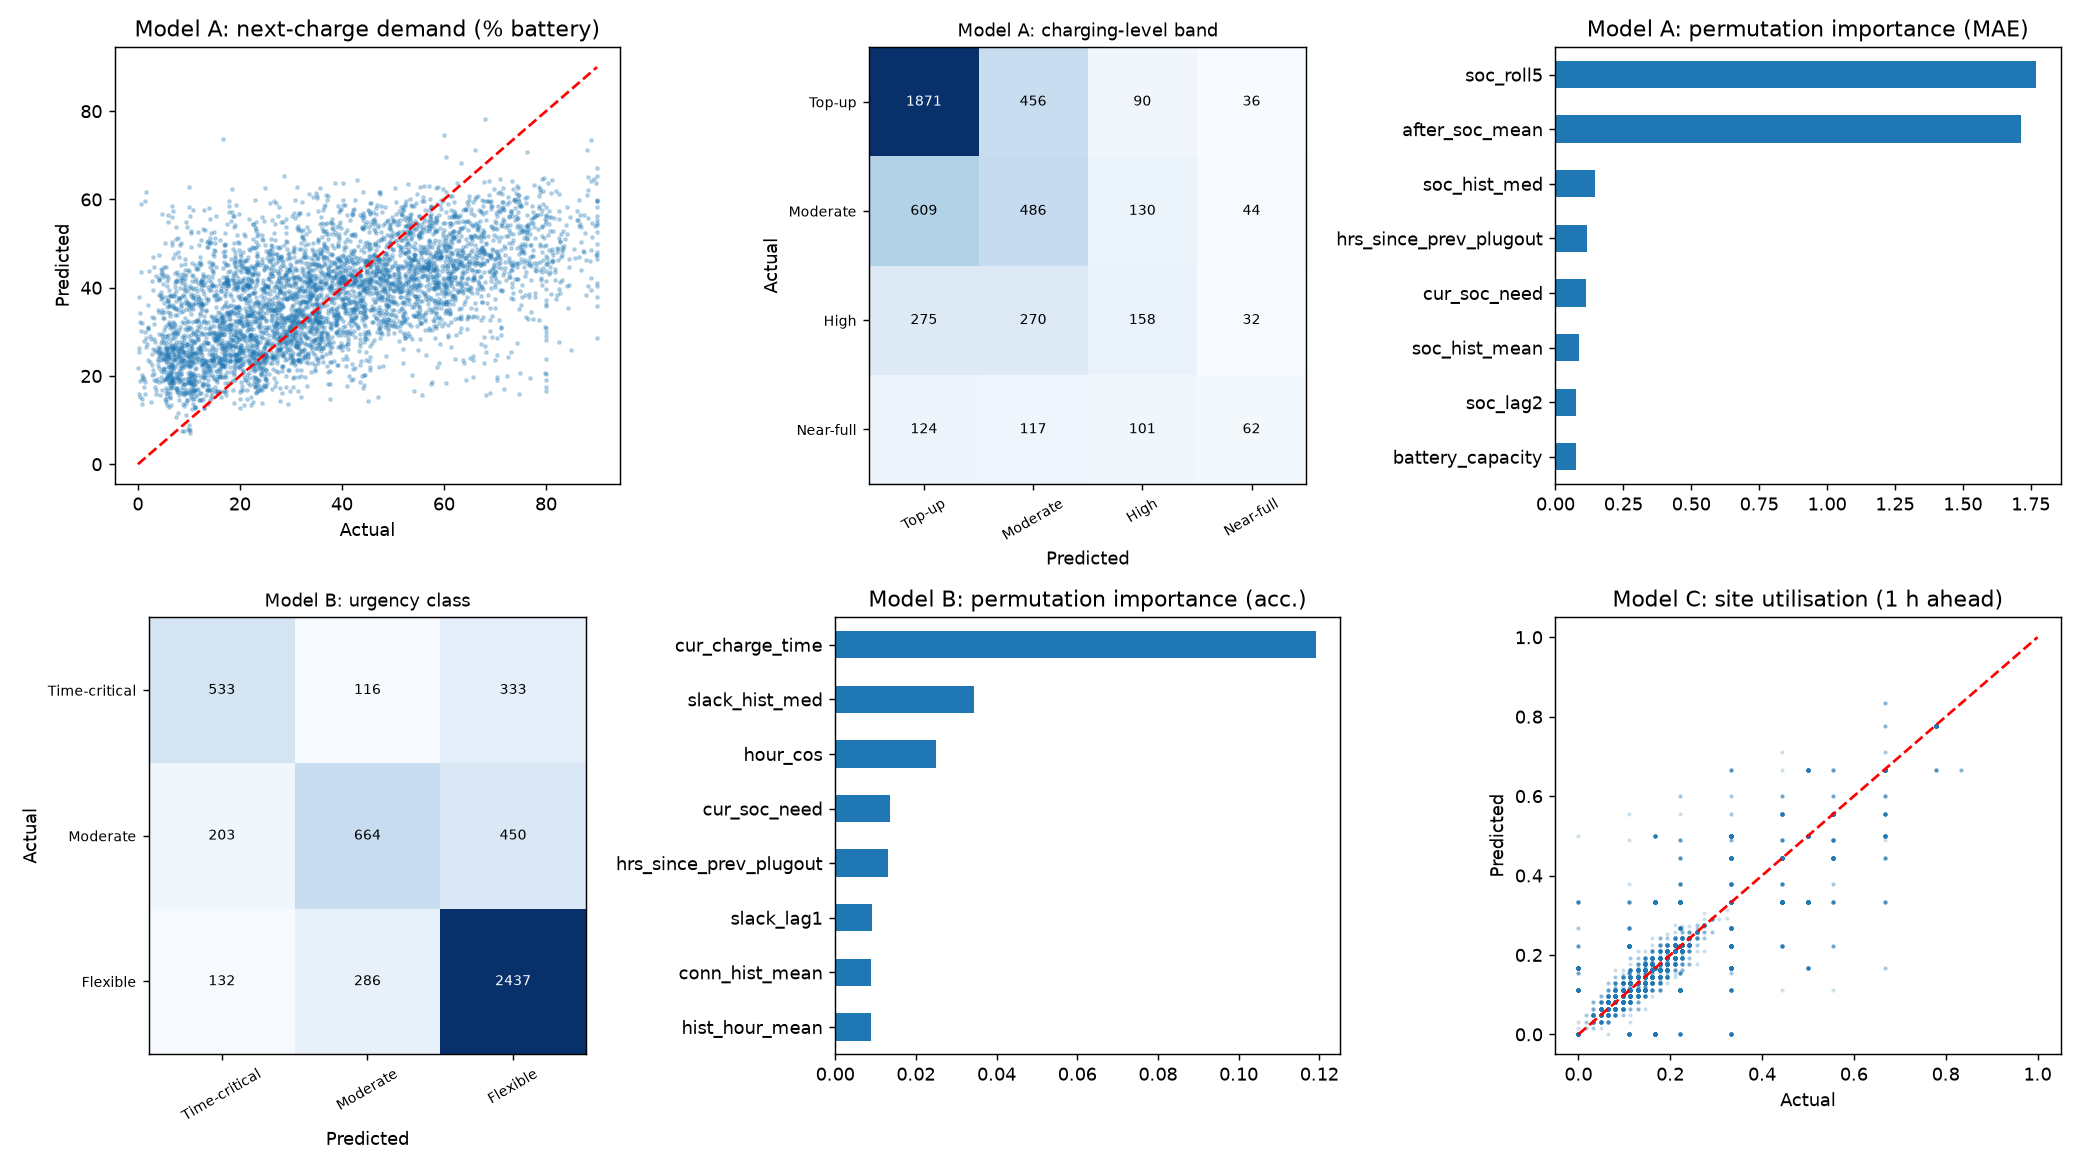

In [19]:
make_plots(pa, pb, pc, OUT_DIR)
from IPython.display import Image
Image(f"{OUT_DIR}/module2_evaluation.png")


## 10. Decision-layer demo

Takes a typical held-out session (predicted demand ≈ 40 %), runs Models A and B, and ranks two hypothetical stations.

In [20]:
qa = joblib.load(f"{OUT_DIR}/modelA_charging_level.joblib"); mb = joblib.load(f"{OUT_DIR}/modelB_urgency.joblib")
pool = df.dropna(subset=["next_soc_need"]).tail(2000)
qp = np.clip(qa["quantile"].predict(pool[FEATS_A]), 0, 90)
i = int(np.argmin(np.abs(qp - 40)))
row, dem = pool.iloc[[i]], float(qp[i])
urg = int(mb["clf"].predict(row[FEATS_B])[0])
ranked, tgt, msg = recommend_option(
    current_soc=30, battery_kwh=float(row.battery_capacity.iloc[0]), pred_demand_q_pct=dem, urgency_class=urg,
    candidates=[dict(name="Station 1 (nearer, busy, 7 kW)", distance_km=1.0, power_kw=7, pred_utilisation=0.75),
                dict(name="Station 2 (farther, free, 22 kW)", distance_km=3.5, power_kw=22, pred_utilisation=0.15)])
print(msg)
pd.DataFrame(ranked)


Charge to 55% (16.7 kWh) at Station 2 (farther, free, 22 kW) [Time-critical user].


,name,travel_min,wait_min,charge_min,total_min,stress_penalty,score
0,"Station 2 (farther, free, 22 kW)",7.0,8.0,91.1,106.1,0.0,169.8
1,"Station 1 (nearer, busy, 7 kW)",2.0,214.7,143.1,359.8,0.0,575.7


In [21]:
json.dump(dict(model_A_charging_level=resA, model_B_urgency=resB, model_C_congestion=resC),
          open(f"{OUT_DIR}/module2_metrics.json", "w"), indent=2)
print("saved metrics + models to", OUT_DIR)


saved metrics + models to ./module2_outputs


## Notes & limitations
- Model A's 4-band accuracy is only slightly above the majority-class baseline; next-charge demand is inherently noisy. The 85th-percentile target is its useful output.
- Model C matches the 'same as last hour' baseline at a 1-hour horizon.
- Congestion is a proxy from residential-site occupancy; real station wait-time data would replace it.
- Test users also appear in training (no cold-start evaluation here). Federated training (FedAvg, FedProx, FedPer), a cold-start test for new users and SHAP explanations are in `02_charging_recommendation_federated.ipynb`.